In [5]:
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical analysis
from scipy import stats

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)

print("Libraries imported successfully!")

Libraries imported successfully!


In [6]:
# Block 2: Load the Dataset

# Load the CSV file
df = pd.read_csv("Crop_recommendation.csv")

# Display the first five rows
print("First 5 rows of the dataset:")
display(df.head())

First 5 rows of the dataset:


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [7]:
# Block 3: Understand the Dataset Structure

# Check the number of rows and columns
print("Dataset Shape:", df.shape)

# Check column names
print("\nColumn Names:")
print(df.columns.tolist())

# Check data types and non-null counts
print("\nDataset Information:")
df.info()

# Display the number of unique values in each column
print("\nUnique Values in Each Column:")
print(df.nunique())

Dataset Shape: (2200, 8)

Column Names:
['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 153.0 KB

Unique Values in Each Column:
N               137
P               117
K                73
temperature    2200
humidity       2200
ph             2200
rainfall       2200
label            22
dtype: int64


In [8]:
# Block 4: Check Data Quality

# 1. Check missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# 2. Check total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

# 3. Check duplicate rows
print("\nTotal Duplicate Rows:", df.duplicated().sum())

# 4. Check the percentage of missing values
print("\nMissing Values Percentage:")
print((df.isnull().sum() / len(df)) * 100)

Missing Values:
N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Total Missing Values: 0

Total Duplicate Rows: 0

Missing Values Percentage:
N              0.0
P              0.0
K              0.0
temperature    0.0
humidity       0.0
ph             0.0
rainfall       0.0
label          0.0
dtype: float64


In [9]:
# Block 5: Statistical Summary

# Calculate descriptive statistics for numerical columns
print("Descriptive Statistical Summary:")
display(df.describe().round(2))

# Check the number of unique crop types
print("\nNumber of Unique Crop Types:", df["label"].nunique())

# Display all crop types
print("\nAvailable Crop Types:")
print(sorted(df["label"].unique()))

# Count records for each crop
print("\nRecords Per Crop:")
print(df["label"].value_counts().sort_index())

Descriptive Statistical Summary:


,N,P,K,temperature,humidity,ph,rainfall
count,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00,2200.00
mean,50.55,53.36,48.15,25.62,71.48,6.47,103.46
std,36.92,32.99,50.65,5.06,22.26,0.77,54.96
min,0.00,5.00,5.00,8.83,14.26,3.50,20.21
25%,21.00,28.00,20.00,22.77,60.26,5.97,64.55
50%,37.00,51.00,32.00,25.60,80.47,6.43,94.87
75%,84.25,68.00,49.00,28.56,89.95,6.92,124.27
max,140.00,145.00,205.00,43.68,99.98,9.94,298.56



Number of Unique Crop Types: 22

Available Crop Types:
['apple', 'banana', 'blackgram', 'chickpea', 'coconut', 'coffee', 'cotton', 'grapes', 'jute', 'kidneybeans', 'lentil', 'maize', 'mango', 'mothbeans', 'mungbean', 'muskmelon', 'orange', 'papaya', 'pigeonpeas', 'pomegranate', 'rice', 'watermelon']

Records Per Crop:
label
apple          100
banana         100
blackgram      100
chickpea       100
coconut        100
coffee         100
cotton         100
grapes         100
jute           100
kidneybeans    100
lentil         100
maize          100
mango          100
mothbeans      100
mungbean       100
muskmelon      100
orange         100
papaya         100
pigeonpeas     100
pomegranate    100
rice           100
watermelon     100
Name: count, dtype: int64


Number of Records for Each Crop:
label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


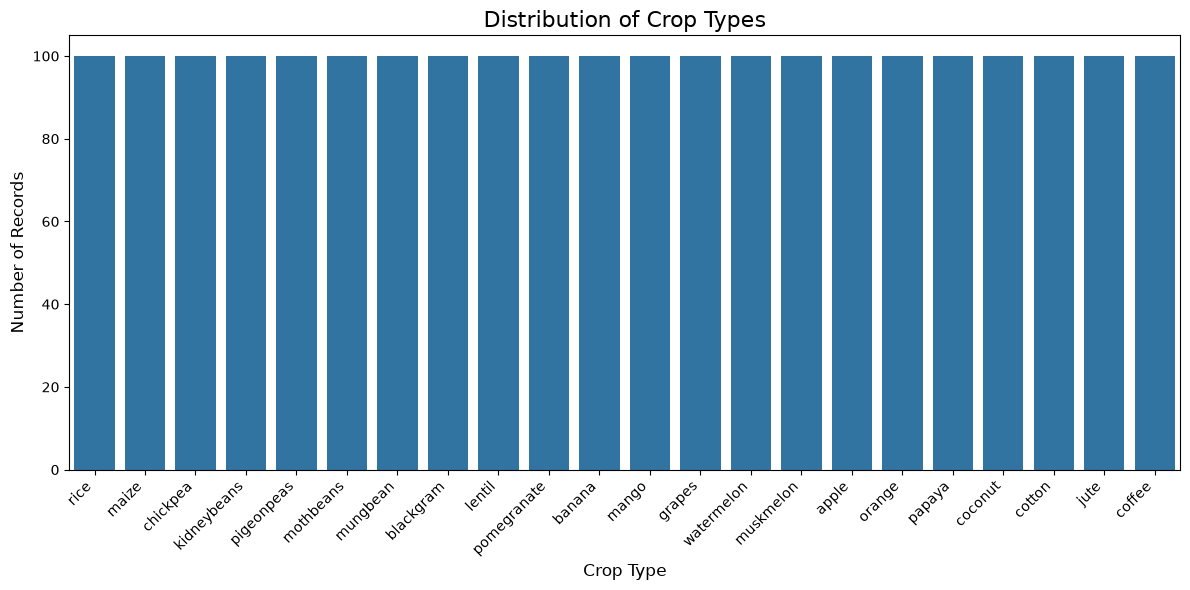

In [10]:
# Block 6: Crop Distribution Analysis

# Count the number of records for each crop
crop_counts = df["label"].value_counts().sort_values(ascending=False)

# Display the crop counts
print("Number of Records for Each Crop:")
print(crop_counts)

# Visualize crop distribution
plt.figure(figsize=(12, 6))

sns.barplot(
    x=crop_counts.index,
    y=crop_counts.values
)

plt.title("Distribution of Crop Types", fontsize=16)
plt.xlabel("Crop Type", fontsize=12)
plt.ylabel("Number of Records", fontsize=12)
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

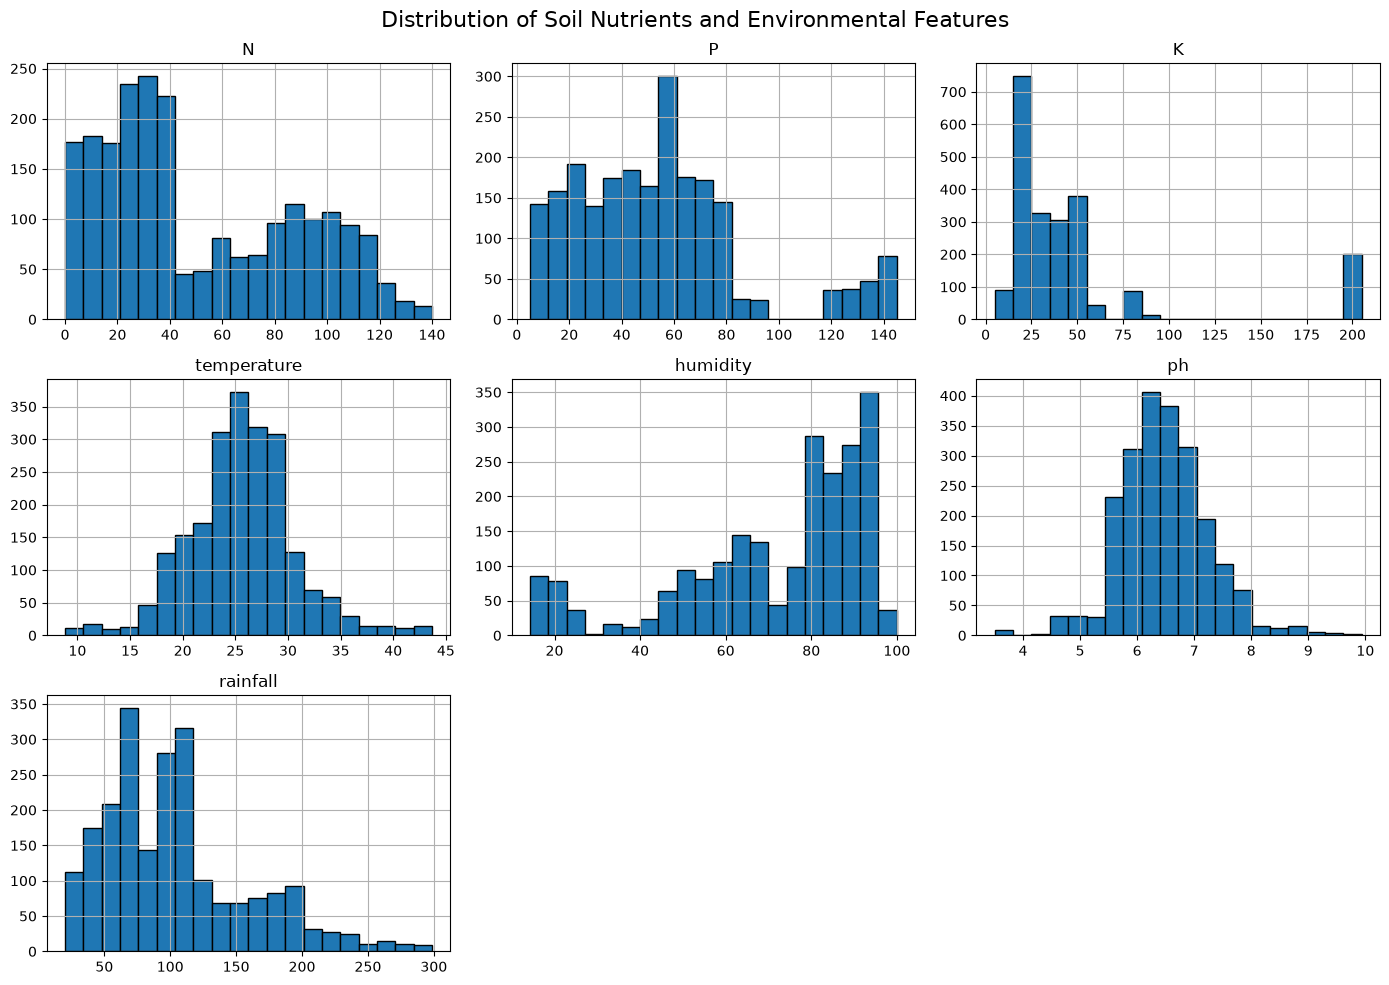

In [11]:
# Block 7: Feature Distribution Analysis

# Select numerical features
numerical_features = [
    "N", "P", "K", "temperature",
    "humidity", "ph", "rainfall"
]

# Display histograms for all numerical features
df[numerical_features].hist(
    figsize=(14, 10),
    bins=20,
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Soil Nutrients and Environmental Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

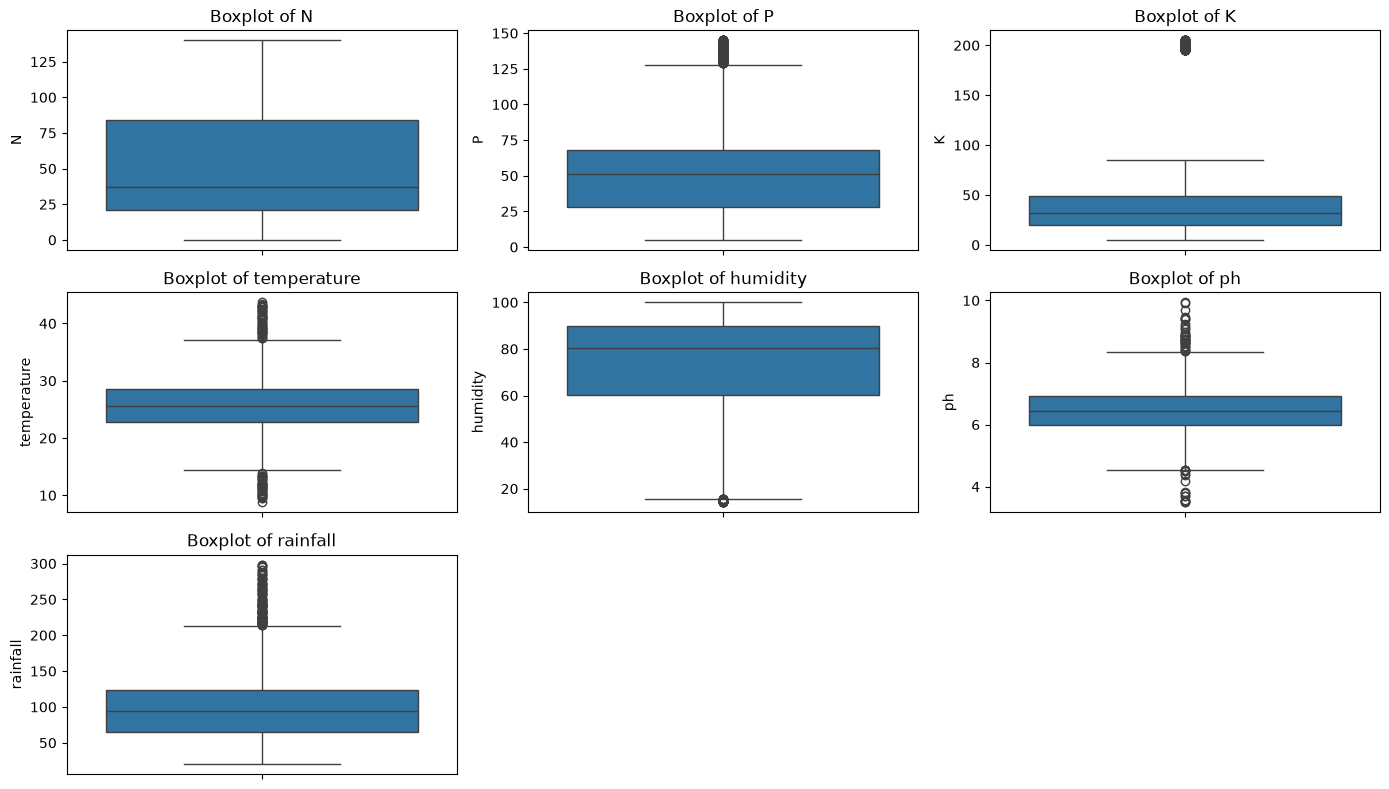

In [12]:
# Block 8: Outlier Detection Using Boxplots

# Select numerical features
numerical_features = [
    "N", "P", "K", "temperature",
    "humidity", "ph", "rainfall"
]

# Create boxplots for all numerical features
plt.figure(figsize=(14, 8))

for i, column in enumerate(numerical_features, 1):
    plt.subplot(3, 3, i)
    
    sns.boxplot(y=df[column])
    
    plt.title(f"Boxplot of {column}")
    plt.ylabel(column)

plt.tight_layout()
plt.show()

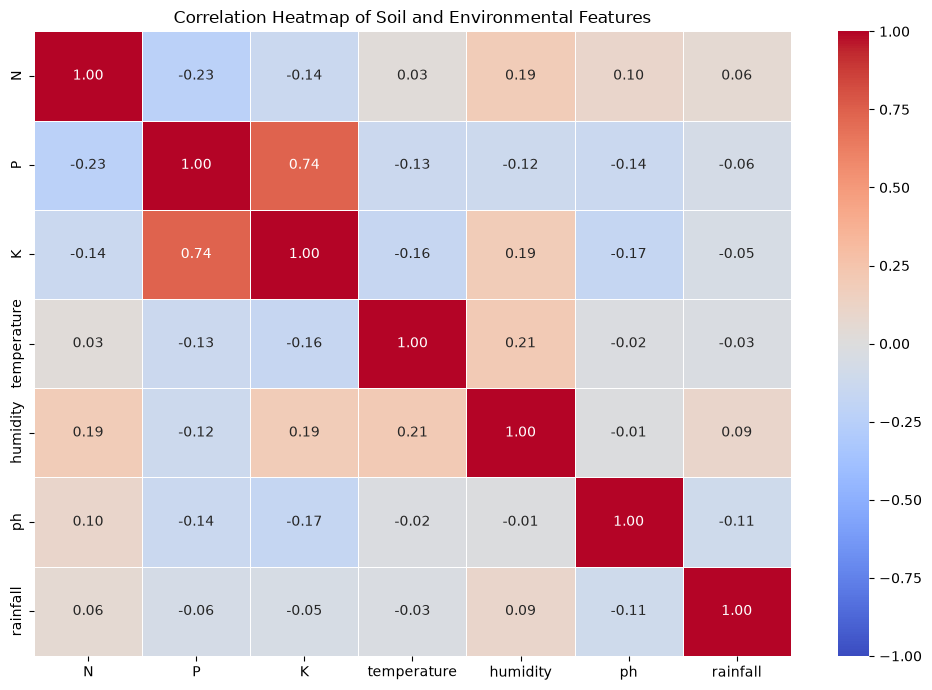

In [13]:
# Block 9: Correlation Analysis

# Calculate correlations between numerical features
correlation_matrix = df[
    ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
].corr()

# Create the correlation heatmap
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Soil and Environmental Features")
plt.tight_layout()
plt.show()

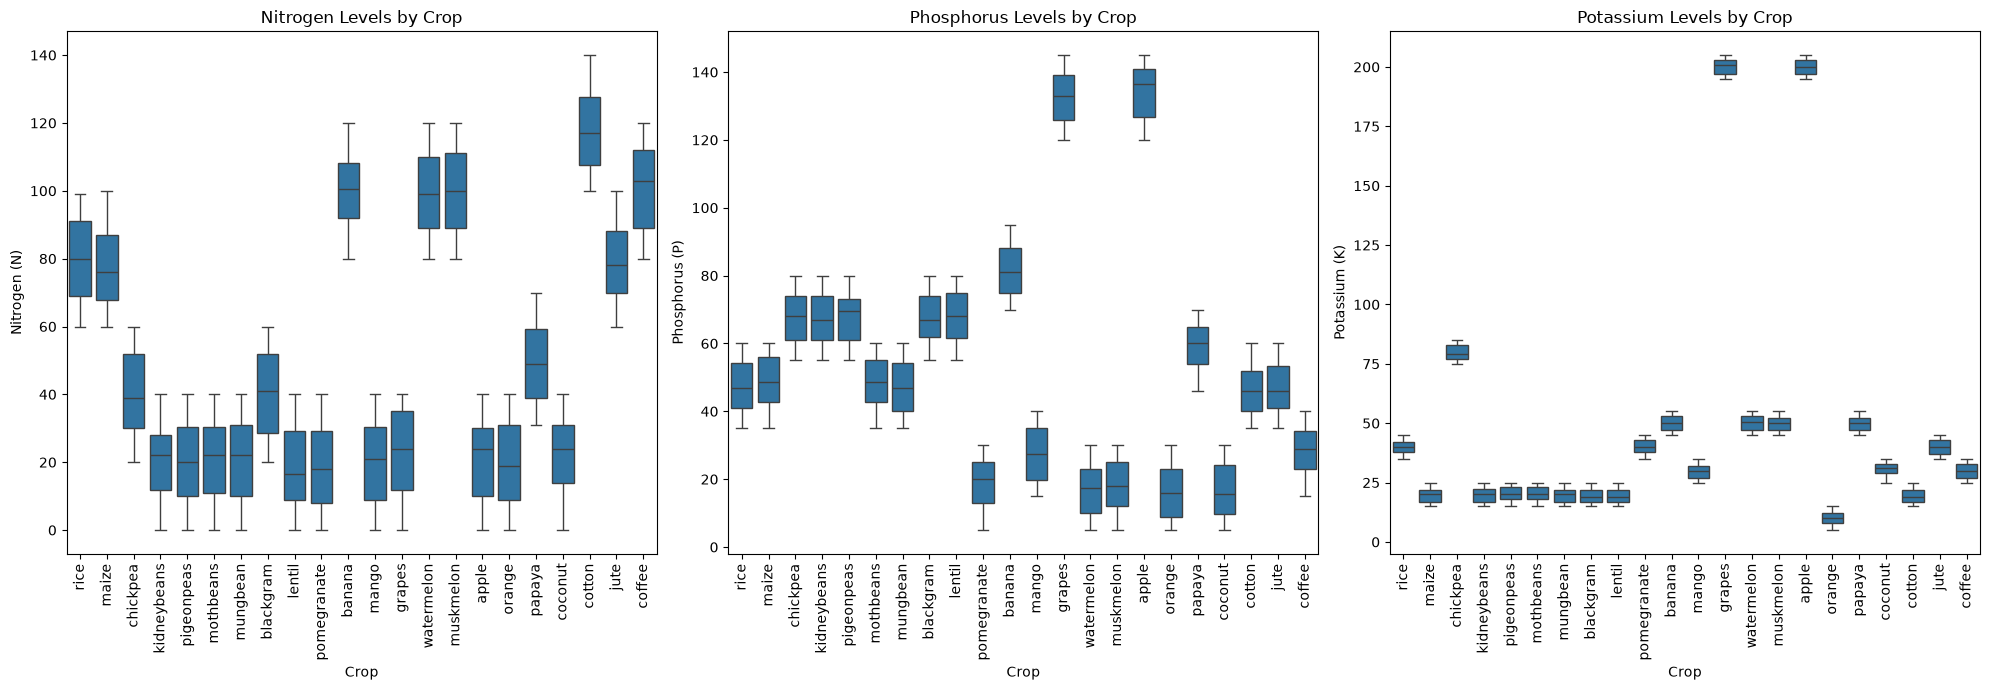

In [14]:
# Block 10: Soil Nutrient Analysis by Crop

# Create three visualizations
fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# Nitrogen distribution
sns.boxplot(data=df, x="label", y="N", ax=axes[0])
axes[0].set_title("Nitrogen Levels by Crop")
axes[0].set_xlabel("Crop")
axes[0].set_ylabel("Nitrogen (N)")
axes[0].tick_params(axis="x", rotation=90)

# Phosphorus distribution
sns.boxplot(data=df, x="label", y="P", ax=axes[1])
axes[1].set_title("Phosphorus Levels by Crop")
axes[1].set_xlabel("Crop")
axes[1].set_ylabel("Phosphorus (P)")
axes[1].tick_params(axis="x", rotation=90)

# Potassium distribution
sns.boxplot(data=df, x="label", y="K", ax=axes[2])
axes[2].set_title("Potassium Levels by Crop")
axes[2].set_xlabel("Crop")
axes[2].set_ylabel("Potassium (K)")
axes[2].tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

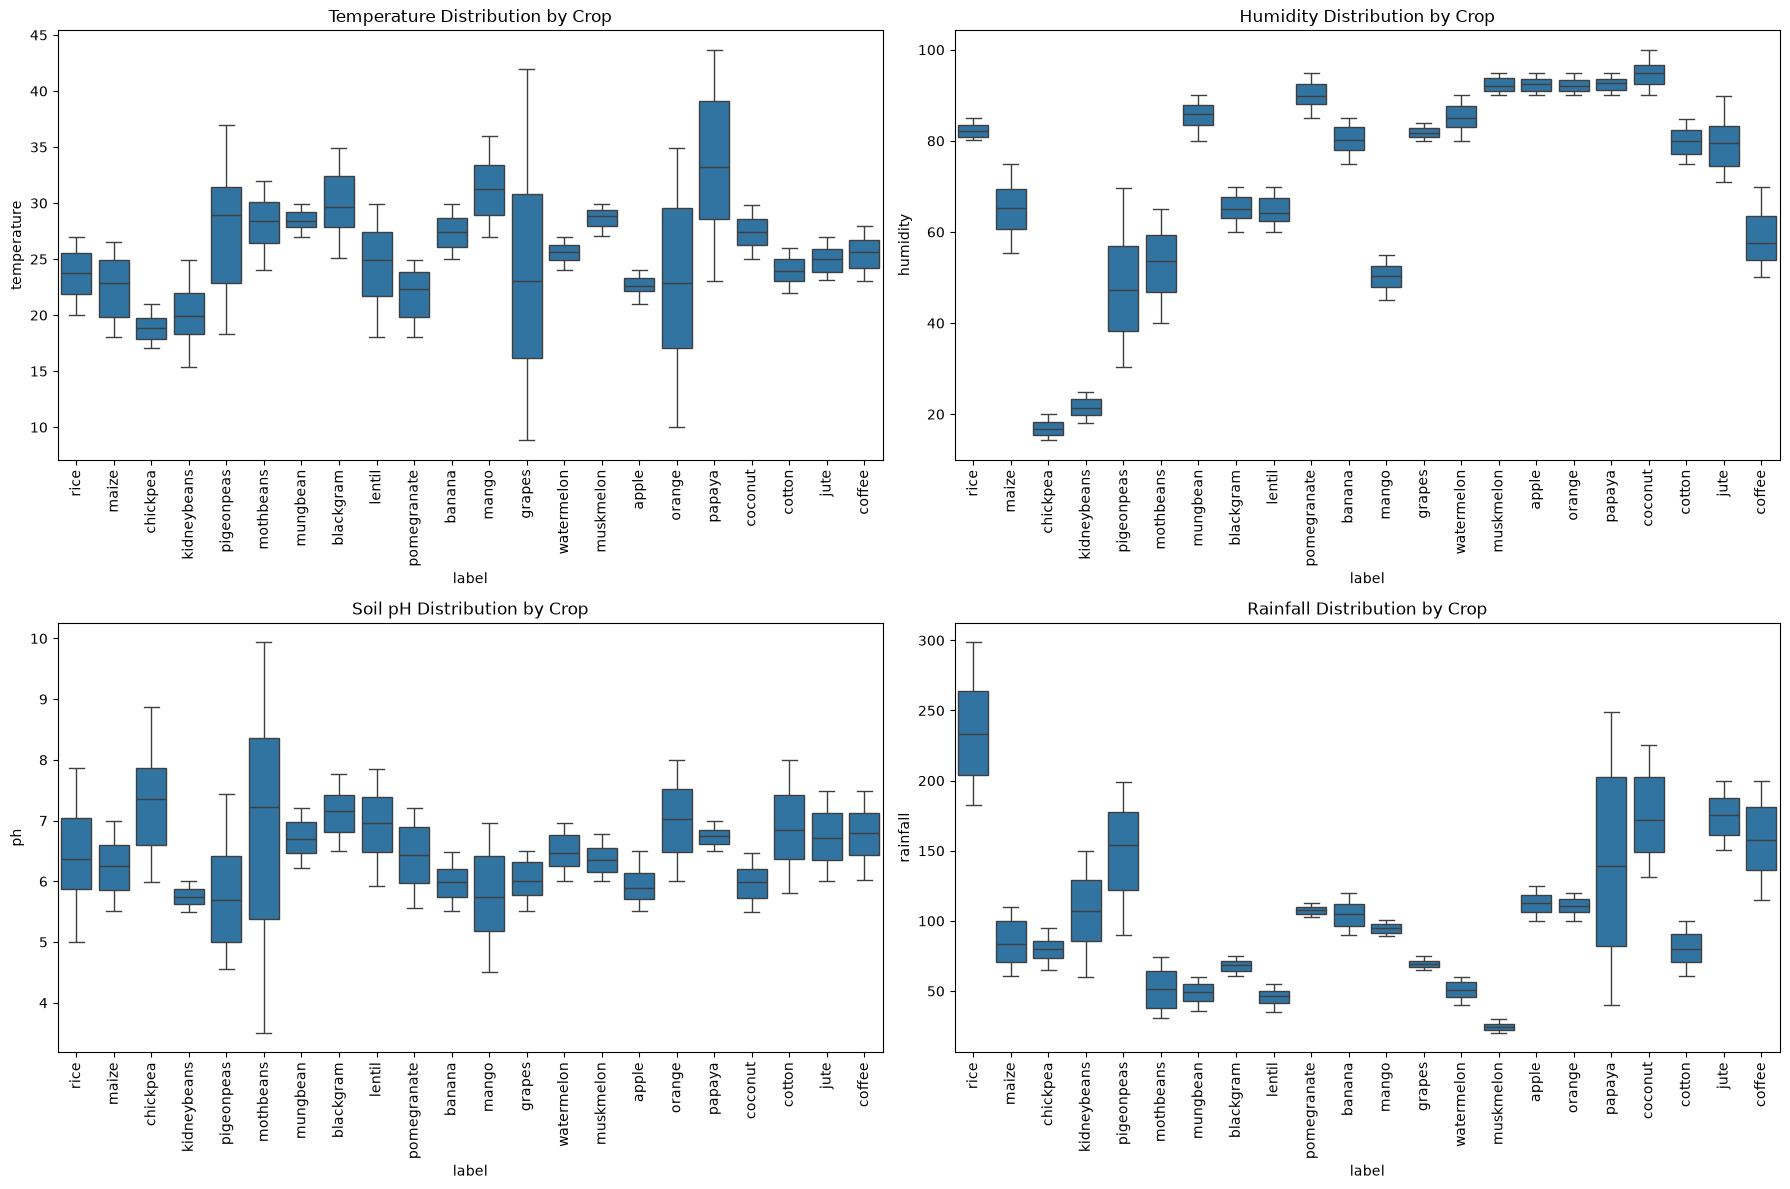

In [15]:
# Block 11: Environmental Conditions Analysis by Crop

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Temperature by crop
sns.boxplot(data=df, x="label", y="temperature", ax=axes[0, 0])
axes[0, 0].set_title("Temperature Distribution by Crop")
axes[0, 0].tick_params(axis="x", rotation=90)

# Humidity by crop
sns.boxplot(data=df, x="label", y="humidity", ax=axes[0, 1])
axes[0, 1].set_title("Humidity Distribution by Crop")
axes[0, 1].tick_params(axis="x", rotation=90)

# Soil pH by crop
sns.boxplot(data=df, x="label", y="ph", ax=axes[1, 0])
axes[1, 0].set_title("Soil pH Distribution by Crop")
axes[1, 0].tick_params(axis="x", rotation=90)

# Rainfall by crop
sns.boxplot(data=df, x="label", y="rainfall", ax=axes[1, 1])
axes[1, 1].set_title("Rainfall Distribution by Crop")
axes[1, 1].tick_params(axis="x", rotation=90)

plt.tight_layout()
plt.show()

In [16]:
# Block 12: One-Way ANOVA for Numerical Features

from scipy.stats import f_oneway

# Numerical features to analyze
numerical_features = [
    "N", "P", "K", "temperature",
    "humidity", "ph", "rainfall"
]

# Store the statistical results
anova_results = []

# Perform ANOVA for each feature
for feature in numerical_features:

    # Divide feature values into groups based on crop type
    groups = [
        group[feature].values
        for _, group in df.groupby("label", observed=True)
    ]

    # Perform one-way ANOVA
    f_statistic, p_value = f_oneway(*groups)

    # Store results
    anova_results.append({
        "Feature": feature,
        "F-Statistic": f_statistic,
        "P-Value": p_value,
        "Significant": "Yes" if p_value < 0.05 else "No"
    })

# Convert results into a DataFrame
anova_df = pd.DataFrame(anova_results)

# Display results
print("One-Way ANOVA Results:")
display(anova_df.round(6))

One-Way ANOVA Results:


,Feature,F-Statistic,P-Value,Significant
0,N,897.568186,0.0,Yes
1,P,1885.657859,0.0,Yes
2,K,27238.362067,0.0,Yes
3,temperature,102.186981,0.0,Yes
4,humidity,3103.708891,0.0,Yes
5,ph,60.344034,0.0,Yes
6,rainfall,605.527966,0.0,Yes


In [17]:
# Block 13: Separate Features and Target

# Input features (soil and environmental conditions)
X = df.drop("label", axis=1)

# Target variable (crop to be recommended)
y = df["label"]

# Display the dimensions
print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

# Display the input features
print("\nInput Features:")
print(X.head())

# Display the target variable
print("\nTarget Labels:")
print(y.head())

# Count the number of crop categories
print("\nNumber of Crop Categories:", y.nunique())

Features Shape: (2200, 7)
Target Shape: (2200,)

Input Features:
    N   P   K  temperature   humidity        ph    rainfall
0  90  42  43    20.879744  82.002744  6.502985  202.935536
1  85  58  41    21.770462  80.319644  7.038096  226.655537
2  60  55  44    23.004459  82.320763  7.840207  263.964248
3  74  35  40    26.491096  80.158363  6.980401  242.864034
4  78  42  42    20.130175  81.604873  7.628473  262.717340

Target Labels:
0    rice
1    rice
2    rice
3    rice
4    rice
Name: label, dtype: str

Number of Crop Categories: 22


In [18]:
# Block 14: Train-Test Split

from sklearn.model_selection import train_test_split

# Split the dataset: 80% training and 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display dataset dimensions
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("\nTraining Target:", y_train.shape)
print("Testing Target:", y_test.shape)

# Verify crop distribution
print("\nCrop Distribution in Training Data:")
print(y_train.value_counts().sort_index())

print("\nCrop Distribution in Testing Data:")
print(y_test.value_counts().sort_index())

Training Features: (1760, 7)
Testing Features: (440, 7)

Training Target: (1760,)
Testing Target: (440,)

Crop Distribution in Training Data:
label
apple          80
banana         80
blackgram      80
chickpea       80
coconut        80
coffee         80
cotton         80
grapes         80
jute           80
kidneybeans    80
lentil         80
maize          80
mango          80
mothbeans      80
mungbean       80
muskmelon      80
orange         80
papaya         80
pigeonpeas     80
pomegranate    80
rice           80
watermelon     80
Name: count, dtype: int64

Crop Distribution in Testing Data:
label
apple          20
banana         20
blackgram      20
chickpea       20
coconut        20
coffee         20
cotton         20
grapes         20
jute           20
kidneybeans    20
lentil         20
maize          20
mango          20
mothbeans      20
mungbean       20
muskmelon      20
orange         20
papaya         20
pigeonpeas     20
pomegranate    20
rice           20
watermelon

In [19]:
# Block 15: Logistic Regression - Training and Evaluation

from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 1. Feature Scaling
scaler_lr = StandardScaler()

X_train_scaled_lr = scaler_lr.fit_transform(X_train)
X_test_scaled_lr = scaler_lr.transform(X_test)

# 2. Initialize the Model
lr_model = LogisticRegression(
    max_iter=2000,
    random_state=42
)

# 3. Train the Model
lr_model.fit(X_train_scaled_lr, y_train)

print("Logistic Regression trained successfully!")

# 4. Make Predictions
y_pred_lr = lr_model.predict(X_test_scaled_lr)

# 5. Predict Probabilities for ROC-AUC
y_prob_lr = lr_model.predict_proba(X_test_scaled_lr)

# 6. Calculate Evaluation Metrics
lr_accuracy = accuracy_score(y_test, y_pred_lr)

lr_precision = precision_score(
    y_test, y_pred_lr,
    average="macro",
    zero_division=0
)

lr_recall = recall_score(
    y_test, y_pred_lr,
    average="macro",
    zero_division=0
)

lr_f1 = f1_score(
    y_test, y_pred_lr,
    average="macro",
    zero_division=0
)

lr_roc_auc = roc_auc_score(
    y_test,
    y_prob_lr,
    multi_class="ovr",
    average="macro",
    labels=lr_model.classes_
)

# 7. Display All Evaluation Metrics
print("\n===== LOGISTIC REGRESSION RESULTS =====")
print(f"Accuracy:  {lr_accuracy:.4f} ({lr_accuracy * 100:.2f}%)")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall:    {lr_recall:.4f}")
print(f"F1-Score:  {lr_f1:.4f}")
print(f"ROC-AUC:   {lr_roc_auc:.4f}")

Logistic Regression trained successfully!

===== LOGISTIC REGRESSION RESULTS =====
Accuracy:  0.9727 (97.27%)
Precision: 0.9740
Recall:    0.9727
F1-Score:  0.9725
ROC-AUC:   0.9998


In [20]:
# Block 16: Decision Tree - Training and Evaluation

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 1. Initialize the model
dt_model = DecisionTreeClassifier(random_state=42)

# 2. Train the model
dt_model.fit(X_train, y_train)

print("Decision Tree trained successfully!")

# 3. Make predictions
y_pred_dt = dt_model.predict(X_test)

# 4. Predict probabilities for ROC-AUC
y_prob_dt = dt_model.predict_proba(X_test)

# 5. Calculate evaluation metrics
dt_accuracy = accuracy_score(y_test, y_pred_dt)

dt_precision = precision_score(
    y_test, y_pred_dt,
    average="macro",
    zero_division=0
)

dt_recall = recall_score(
    y_test, y_pred_dt,
    average="macro",
    zero_division=0
)

dt_f1 = f1_score(
    y_test, y_pred_dt,
    average="macro",
    zero_division=0
)

dt_roc_auc = roc_auc_score(
    y_test,
    y_prob_dt,
    multi_class="ovr",
    average="macro",
    labels=dt_model.classes_
)

# 6. Display results
print("\n===== DECISION TREE RESULTS =====")
print(f"Accuracy:  {dt_accuracy:.4f} ({dt_accuracy * 100:.2f}%)")
print(f"Precision: {dt_precision:.4f}")
print(f"Recall:    {dt_recall:.4f}")
print(f"F1-Score:  {dt_f1:.4f}")
print(f"ROC-AUC:   {dt_roc_auc:.4f}")

Decision Tree trained successfully!

===== DECISION TREE RESULTS =====
Accuracy:  0.9795 (97.95%)
Precision: 0.9806
Recall:    0.9795
F1-Score:  0.9794
ROC-AUC:   0.9893


In [21]:
# Block 17: Random Forest - Training and Evaluation

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 1. Initialize the model
rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

# 2. Train the model
rf_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

# 3. Make predictions
y_pred_rf = rf_model.predict(X_test)

# 4. Predict probabilities for ROC-AUC
y_prob_rf = rf_model.predict_proba(X_test)

# 5. Calculate evaluation metrics
rf_accuracy = accuracy_score(y_test, y_pred_rf)

rf_precision = precision_score(
    y_test, y_pred_rf,
    average="macro",
    zero_division=0
)

rf_recall = recall_score(
    y_test, y_pred_rf,
    average="macro",
    zero_division=0
)

rf_f1 = f1_score(
    y_test, y_pred_rf,
    average="macro",
    zero_division=0
)

rf_roc_auc = roc_auc_score(
    y_test,
    y_prob_rf,
    multi_class="ovr",
    average="macro",
    labels=rf_model.classes_
)

# 6. Display results
print("\n===== RANDOM FOREST RESULTS =====")
print(f"Accuracy:  {rf_accuracy:.4f} ({rf_accuracy * 100:.2f}%)")
print(f"Precision: {rf_precision:.4f}")
print(f"Recall:    {rf_recall:.4f}")
print(f"F1-Score:  {rf_f1:.4f}")
print(f"ROC-AUC:   {rf_roc_auc:.4f}")

Random Forest trained successfully!

===== RANDOM FOREST RESULTS =====
Accuracy:  0.9955 (99.55%)
Precision: 0.9957
Recall:    0.9955
F1-Score:  0.9955
ROC-AUC:   1.0000


In [22]:
# Block 18: Gradient Boosting - Training and Evaluation

from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 1. Initialize the model
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

# 2. Train the model
gb_model.fit(X_train, y_train)

print("Gradient Boosting trained successfully!")

# 3. Make predictions
y_pred_gb = gb_model.predict(X_test)

# 4. Predict probabilities for ROC-AUC
y_prob_gb = gb_model.predict_proba(X_test)

# 5. Calculate evaluation metrics
gb_accuracy = accuracy_score(y_test, y_pred_gb)

gb_precision = precision_score(
    y_test, y_pred_gb,
    average="macro",
    zero_division=0
)

gb_recall = recall_score(
    y_test, y_pred_gb,
    average="macro",
    zero_division=0
)

gb_f1 = f1_score(
    y_test, y_pred_gb,
    average="macro",
    zero_division=0
)

gb_roc_auc = roc_auc_score(
    y_test,
    y_prob_gb,
    multi_class="ovr",
    average="macro",
    labels=gb_model.classes_
)

# 6. Display results
print("\n===== GRADIENT BOOSTING RESULTS =====")
print(f"Accuracy:  {gb_accuracy:.4f} ({gb_accuracy * 100:.2f}%)")
print(f"Precision: {gb_precision:.4f}")
print(f"Recall:    {gb_recall:.4f}")
print(f"F1-Score:  {gb_f1:.4f}")
print(f"ROC-AUC:   {gb_roc_auc:.4f}")

Gradient Boosting trained successfully!

===== GRADIENT BOOSTING RESULTS =====
Accuracy:  0.9886 (98.86%)
Precision: 0.9897
Recall:    0.9886
F1-Score:  0.9887
ROC-AUC:   1.0000


In [23]:
# Block 19: SVM - Training and Evaluation

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# 1. Feature scaling
scaler_svm = StandardScaler()

X_train_scaled_svm = scaler_svm.fit_transform(X_train)
X_test_scaled_svm = scaler_svm.transform(X_test)

# 2. Initialize the model
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    probability=True,
    random_state=42
)

# 3. Train the model
svm_model.fit(X_train_scaled_svm, y_train)

print("SVM trained successfully!")

# 4. Make predictions
y_pred_svm = svm_model.predict(X_test_scaled_svm)

# 5. Predict probabilities for ROC-AUC
y_prob_svm = svm_model.predict_proba(X_test_scaled_svm)

# 6. Calculate evaluation metrics
svm_accuracy = accuracy_score(y_test, y_pred_svm)

svm_precision = precision_score(
    y_test, y_pred_svm,
    average="macro",
    zero_division=0
)

svm_recall = recall_score(
    y_test, y_pred_svm,
    average="macro",
    zero_division=0
)

svm_f1 = f1_score(
    y_test, y_pred_svm,
    average="macro",
    zero_division=0
)

svm_roc_auc = roc_auc_score(
    y_test,
    y_prob_svm,
    multi_class="ovr",
    average="macro",
    labels=svm_model.classes_
)

# 7. Display results
print("\n===== SVM RESULTS =====")
print(f"Accuracy:  {svm_accuracy:.4f} ({svm_accuracy * 100:.2f}%)")
print(f"Precision: {svm_precision:.4f}")
print(f"Recall:    {svm_recall:.4f}")
print(f"F1-Score:  {svm_f1:.4f}")
print(f"ROC-AUC:   {svm_roc_auc:.4f}")

c:\Users\gopal\AppData\Local\Programs\Python\Python313\Lib\site-packages\sklearn\svm\_base.py:239: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


SVM trained successfully!

===== SVM RESULTS =====
Accuracy:  0.9841 (98.41%)
Precision: 0.9856
Recall:    0.9841
F1-Score:  0.9840
ROC-AUC:   1.0000


In [24]:
# Block 20: Compare All Five ML Models

import pandas as pd

# Store evaluation results for all models
results = {
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest",
        "Gradient Boosting",
        "SVM"
    ],

    "Accuracy": [
        lr_accuracy,
        dt_accuracy,
        rf_accuracy,
        gb_accuracy,
        svm_accuracy
    ],

    "Precision": [
        lr_precision,
        dt_precision,
        rf_precision,
        gb_precision,
        svm_precision
    ],

    "Recall": [
        lr_recall,
        dt_recall,
        rf_recall,
        gb_recall,
        svm_recall
    ],

    "F1-Score": [
        lr_f1,
        dt_f1,
        rf_f1,
        gb_f1,
        svm_f1
    ],

    "ROC-AUC": [
        lr_roc_auc,
        dt_roc_auc,
        rf_roc_auc,
        gb_roc_auc,
        svm_roc_auc
    ]
}

# Create comparison DataFrame
comparison_df = pd.DataFrame(results)

# Sort models by accuracy
comparison_df = comparison_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

# Display the comparison table
print("===== COMPARISON OF FIVE MACHINE LEARNING MODELS =====")

display(
    comparison_df.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}"
    }).highlight_max(
        subset=["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"],
        color="lightgreen"
    )
)

# Identify the model with the highest test accuracy
best_model = comparison_df.iloc[0]

print("\n===== BEST MODEL BY TEST ACCURACY =====")
print("Model:", best_model["Model"])
print(f"Accuracy: {best_model['Accuracy']:.4f}")
print(f"Precision: {best_model['Precision']:.4f}")
print(f"Recall: {best_model['Recall']:.4f}")
print(f"F1-Score: {best_model['F1-Score']:.4f}")
print(f"ROC-AUC: {best_model['ROC-AUC']:.4f}")

===== COMPARISON OF FIVE MACHINE LEARNING MODELS =====


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.9955,0.9957,0.9955,0.9955,1.0000
1,Gradient Boosting,0.9886,0.9897,0.9886,0.9887,1.0000
2,SVM,0.9841,0.9856,0.9841,0.9840,1.0000
3,Decision Tree,0.9795,0.9806,0.9795,0.9794,0.9893
4,Logistic Regression,0.9727,0.9740,0.9727,0.9725,0.9998



===== BEST MODEL BY TEST ACCURACY =====
Model: Random Forest
Accuracy: 0.9955
Precision: 0.9957
Recall: 0.9955
F1-Score: 0.9955
ROC-AUC: 1.0000


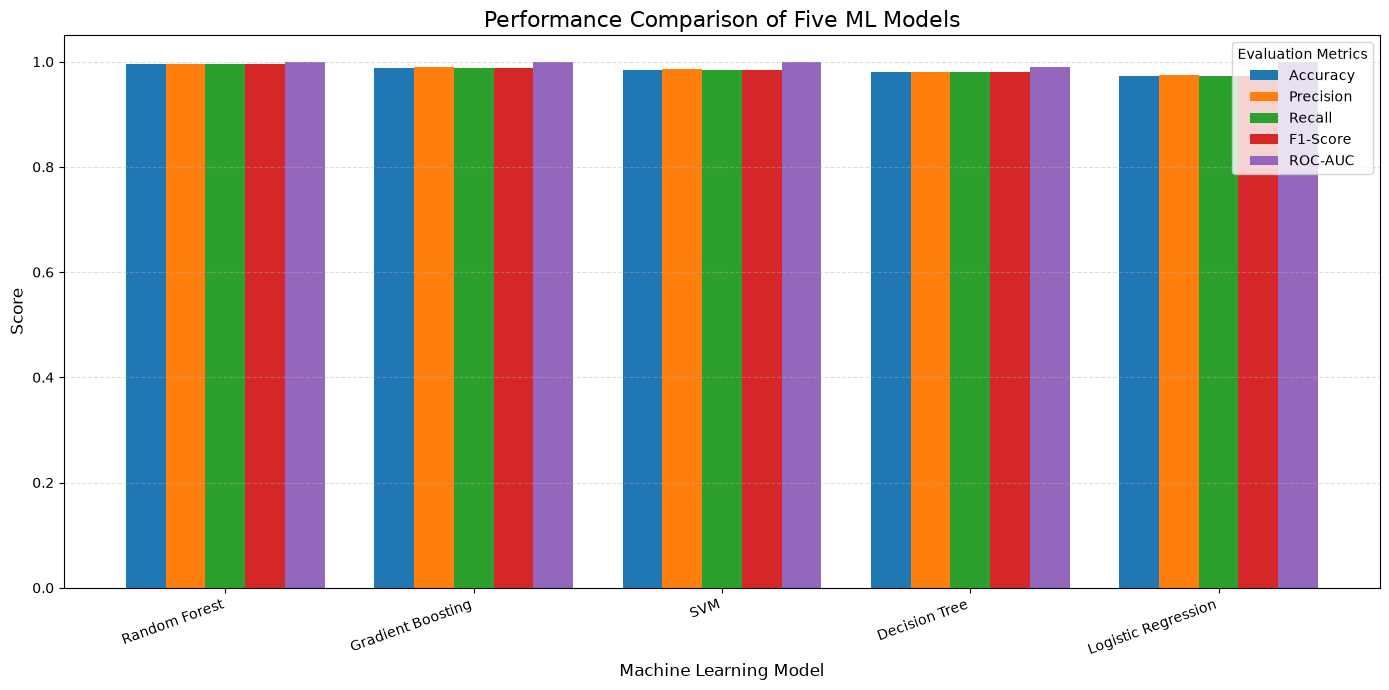

In [25]:
# Block 21: Visual Comparison of Model Performance

import matplotlib.pyplot as plt
import pandas as pd

# Set model names as the index
plot_df = comparison_df.set_index("Model")

# Plot all five evaluation metrics
plot_df[
    ["Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(14, 7),
    width=0.8
)

plt.title("Performance Comparison of Five ML Models", fontsize=16)
plt.xlabel("Machine Learning Model", fontsize=12)
plt.ylabel("Score", fontsize=12)

plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1.05)

plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [26]:
# Block 22: 5-Fold Cross-Validation

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
import pandas as pd

# 1. Define five models
models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000, random_state=42)
    ),

    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        random_state=42
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=1.0, random_state=42)
    )
}

# 2. Define stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 3. Evaluate each model using training data only
cv_results = []

for name, model in models.items():

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Mean CV Accuracy": scores.mean(),
        "Standard Deviation": scores.std()
    })

    print(f"{name}:")
    print(f"  Fold Accuracies: {scores.round(4)}")
    print(f"  Mean Accuracy: {scores.mean():.4f}")
    print(f"  Standard Deviation: {scores.std():.4f}\n")

# 4. Create a comparison table
cv_df = pd.DataFrame(cv_results)

cv_df = cv_df.sort_values(
    by="Mean CV Accuracy",
    ascending=False
).reset_index(drop=True)

print("===== 5-FOLD CROSS-VALIDATION COMPARISON =====")

display(
    cv_df.style.format({
        "Mean CV Accuracy": "{:.4f}",
        "Standard Deviation": "{:.4f}"
    })
)

Logistic Regression:
  Fold Accuracies: [0.9659 0.9574 0.9688 0.9716 0.9773]
  Mean Accuracy: 0.9682
  Standard Deviation: 0.0066

Decision Tree:
  Fold Accuracies: [0.9943 0.9773 0.9886 0.9886 0.9773]
  Mean Accuracy: 0.9852
  Standard Deviation: 0.0068

Random Forest:
  Fold Accuracies: [1.     0.9972 0.983  0.9915 0.9972]
  Mean Accuracy: 0.9938
  Standard Deviation: 0.0061

Gradient Boosting:
  Fold Accuracies: [0.9915 0.983  0.983  0.9886 0.9886]
  Mean Accuracy: 0.9869
  Standard Deviation: 0.0034

SVM:
  Fold Accuracies: [0.9915 0.983  0.9631 0.9716 0.9858]
  Mean Accuracy: 0.9790
  Standard Deviation: 0.0103

===== 5-FOLD CROSS-VALIDATION COMPARISON =====


,Model,Mean CV Accuracy,Standard Deviation
0,Random Forest,0.9938,0.0061
1,Gradient Boosting,0.9869,0.0034
2,Decision Tree,0.9852,0.0068
3,SVM,0.9790,0.0103
4,Logistic Regression,0.9682,0.0066


===== FEATURE IMPORTANCE =====


,Feature,Importance
6,rainfall,0.230184
4,humidity,0.224227
2,K,0.175393
1,P,0.150850
0,N,0.096363
3,temperature,0.072375
5,ph,0.050608


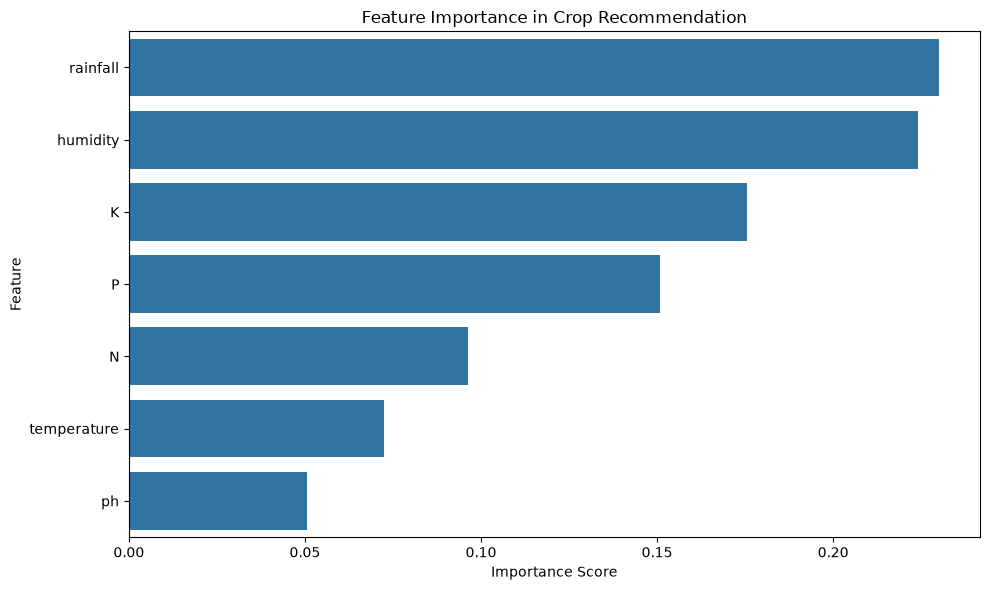

In [27]:
# Block 23: Feature Importance Analysis

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Extract feature importance scores
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display the results
print("===== FEATURE IMPORTANCE =====")
display(feature_importance)

# Visualize feature importance
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance in Crop Recommendation")
plt.xlabel("Importance Score")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

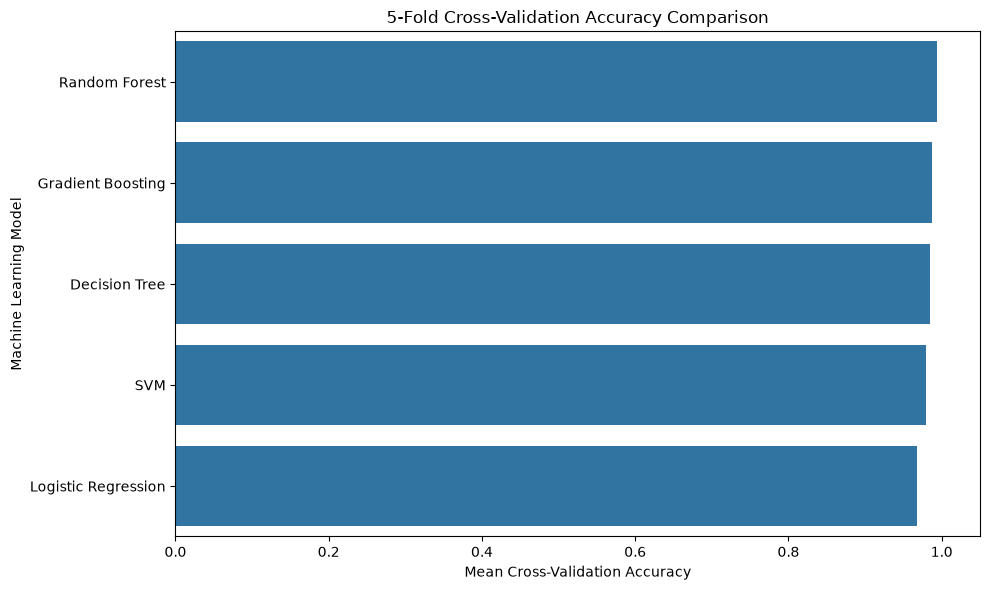

===== CROSS-VALIDATION RESULTS =====


,Model,Mean CV Accuracy,Standard Deviation
0,Random Forest,0.9938,0.0061
1,Gradient Boosting,0.9869,0.0034
2,Decision Tree,0.9852,0.0068
3,SVM,0.9790,0.0103
4,Logistic Regression,0.9682,0.0066


In [28]:
# Block 24: Cross-Validation Accuracy Comparison

import matplotlib.pyplot as plt
import seaborn as sns

# Sort models by mean cross-validation accuracy
cv_plot_df = cv_df.sort_values(
    by="Mean CV Accuracy",
    ascending=False
)

# Create the bar chart
plt.figure(figsize=(10, 6))

sns.barplot(
    data=cv_plot_df,
    x="Mean CV Accuracy",
    y="Model"
)

plt.title("5-Fold Cross-Validation Accuracy Comparison")
plt.xlabel("Mean Cross-Validation Accuracy")
plt.ylabel("Machine Learning Model")

plt.xlim(0, 1.05)
plt.tight_layout()
plt.show()

# Display the cross-validation results
print("===== CROSS-VALIDATION RESULTS =====")

display(
    cv_plot_df.style.format({
        "Mean CV Accuracy": "{:.4f}",
        "Standard Deviation": "{:.4f}"
    })
)

In [29]:
# Block 25: Final Model Comparison

# Merge test-set metrics with cross-validation results
final_results = comparison_df.merge(
    cv_df,
    on="Model",
    how="left"
)

# Sort by test accuracy
final_results = final_results.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

# Display the final results
print("===== FINAL MODEL PERFORMANCE COMPARISON =====")

display(
    final_results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}",
        "ROC-AUC": "{:.4f}",
        "Mean CV Accuracy": "{:.4f}",
        "Standard Deviation": "{:.4f}"
    })
)

# Identify the best model by test accuracy
best_model_name = final_results.loc[0, "Model"]

print("\n===== FINAL RESULT =====")
print("Best model by test accuracy:", best_model_name)
print(
    "Test accuracy:",
    f"{final_results.loc[0, 'Accuracy'] * 100:.2f}%"
)
print(
    "Mean 5-fold CV accuracy:",
    f"{final_results.loc[0, 'Mean CV Accuracy'] * 100:.2f}%"
)

===== FINAL MODEL PERFORMANCE COMPARISON =====


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Mean CV Accuracy,Standard Deviation
0,Random Forest,0.9955,0.9957,0.9955,0.9955,1.0000,0.9938,0.0061
1,Gradient Boosting,0.9886,0.9897,0.9886,0.9887,1.0000,0.9869,0.0034
2,SVM,0.9841,0.9856,0.9841,0.9840,1.0000,0.9790,0.0103
3,Decision Tree,0.9795,0.9806,0.9795,0.9794,0.9893,0.9852,0.0068
4,Logistic Regression,0.9727,0.9740,0.9727,0.9725,0.9998,0.9682,0.0066



===== FINAL RESULT =====
Best model by test accuracy: Random Forest
Test accuracy: 99.55%
Mean 5-fold CV accuracy: 99.38%


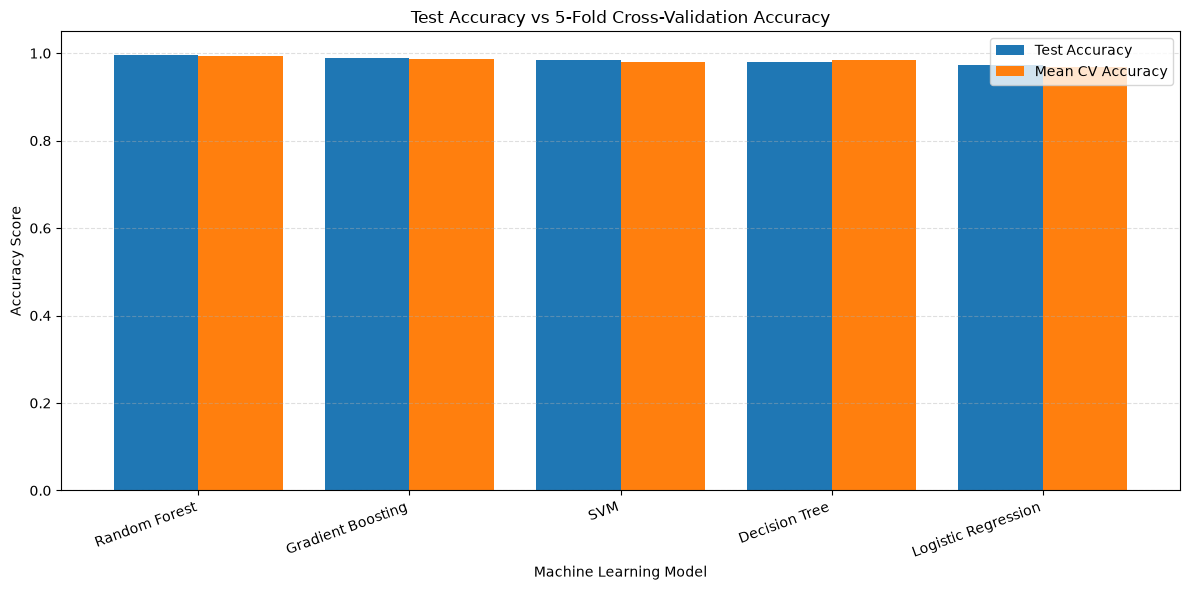

In [30]:
# Block 26: Test Accuracy vs Cross-Validation Accuracy

import pandas as pd
import matplotlib.pyplot as plt

# Prepare the comparison data
accuracy_comparison = final_results[
    ["Model", "Accuracy", "Mean CV Accuracy"]
].copy()

accuracy_comparison = accuracy_comparison.set_index("Model")

# Plot the comparison
accuracy_comparison.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

plt.title("Test Accuracy vs 5-Fold Cross-Validation Accuracy")
plt.xlabel("Machine Learning Model")
plt.ylabel("Accuracy Score")

plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1.05)

plt.legend([
    "Test Accuracy",
    "Mean CV Accuracy"
])

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [31]:
# Block 28: Select and Retrain the Best Model

from sklearn.base import clone

# Select the best model based on test accuracy
best_model_name = final_results.loc[
    final_results["Accuracy"].idxmax(), "Model"
]

# Define the models with their existing configurations
models = {
    "Logistic Regression": lr_model,
    "Decision Tree": dt_model,
    "Random Forest": rf_model,
    "Gradient Boosting": gb_model,
    "SVM": svm_model
}

# Retrieve the selected model
best_model = clone(models[best_model_name])

# Train the selected model using the training data
if best_model_name == "Logistic Regression":
    best_model.fit(X_train_scaled_lr, y_train)

elif best_model_name == "SVM":
    best_model.fit(X_train_scaled_svm, y_train)

else:
    best_model.fit(X_train, y_train)

print("Best Model:", best_model_name)
print("Model retrained successfully!")

Best Model: Random Forest
Model retrained successfully!


In [32]:
# Block 29: Save the Best Model and Required Files

import joblib

# Save the trained model
joblib.dump(best_model, "best_crop_model.pkl")

# Save the scaler if the selected model requires scaling
if best_model_name == "Logistic Regression":
    joblib.dump(scaler_lr, "crop_scaler.pkl")

elif best_model_name == "SVM":
    joblib.dump(scaler_svm, "crop_scaler.pkl")

# Save the input feature names
joblib.dump(list(X.columns), "crop_features.pkl")

# Save the selected model's name (REQUIRED BY app.py)
joblib.dump(best_model_name, "crop_model_name.pkl")

print("Best model and required files saved successfully!")
print("Selected model:", best_model_name)
print("Model file: best_crop_model.pkl")
print("Feature file: crop_features.pkl")
print("Model name file: crop_model_name.pkl")

if best_model_name in ["Logistic Regression", "SVM"]:
    print("Scaler file: crop_scaler.pkl")



Best model and required files saved successfully!
Selected model: Random Forest
Model file: best_crop_model.pkl
Feature file: crop_features.pkl
Model name file: crop_model_name.pkl


In [33]:
# Block 30: Load Saved Model and Predict a Crop

import joblib
import pandas as pd

# 1. Load the saved model and feature names
loaded_model = joblib.load("best_crop_model.pkl")
feature_names = joblib.load("crop_features.pkl")

# 2. Prepare sample input
sample_data = {
    "N": 90,
    "P": 42,
    "K": 43,
    "temperature": 25.5,
    "humidity": 80.0,
    "ph": 6.5,
    "rainfall": 200.0
}

# 3. Convert input into a DataFrame
input_df = pd.DataFrame([sample_data])

# Ensure the feature order matches training
input_df = input_df[feature_names]

# 4. Apply scaling if the selected model requires it
if best_model_name in ["Logistic Regression", "SVM"]:
    loaded_scaler = joblib.load("crop_scaler.pkl")
    input_processed = loaded_scaler.transform(input_df)
else:
    input_processed = input_df

# 5. Predict the crop
predicted_crop = loaded_model.predict(input_processed)[0]

# 6. Display the result
print("===== CROP RECOMMENDATION RESULT =====")
print("Selected Model:", best_model_name)
print("Predicted Crop:", predicted_crop)

===== CROP RECOMMENDATION RESULT =====
Selected Model: Random Forest
Predicted Crop: rice
